In [1]:
import numpy as np
import scipy.sparse as sp
import gurobipy as gp
from gurobipy import GRB, quicksum
import discretizar_problema as disc
import mostrar_y_graficar_solucion as sol
import matplotlib.pyplot as plt
import data_generator as gen
import time

In [58]:
instances = gen.generar_instancias()

In [67]:
coord_x = np.linspace(0,100,21)
coord_y = np.linspace(0,100,21)
grilla = disc.construir_grilla(coord_x,coord_y)
lista_grafos = gen.crear_lista_grafos_adaptados(instances[(0,5)].instances)
tipo_grilla = 'damero'
metrica = 1
dic_intragrilla = disc.diccionario_grilla(grilla,tipo_grilla,metrica)

In [68]:
lista_arcos_dron,lista_arcos_grilla,arcos_por_grafo,listas_pares_por_grafo,salidas_a_grafos_por_nodo_grilla,llegadas_desde_grafos_por_nodo_grilla,salidas_a_grilla_por_nodo_grilla,llegadas_desde_grilla_por_nodo_grilla,lista_salidas_por_nodo_de_grafo,lista_llegadas_por_nodo_de_grafo,dic_indices,nodos_por_indice, lista_dic_completaciones, lista_dic_intragrafo = disc.problema_discretizado(dic_intragrilla,lista_grafos)

In [35]:
m, tiempo_construccion, Z, M, L = disc.modelar_instancia(instances[(0,5)].instances,'damero',1,N_D=60,D=2,orig=(50,50),dest=(50,50),filas=5,columnas=5,G=5)

Set parameter Username
Set parameter LicenseID to value 2697574
Academic license - for non-commercial use only - expires 2026-08-21
Set parameter TimeLimit to value 1.7931612398624420e+03


In [36]:
#m.setParam('TimeLimit',1200.0)
m.optimize()

Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) M-5Y10c CPU @ 0.80GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 5033 rows, 24880 columns and 150198 nonzeros
Model fingerprint: 0x1f93182d
Variable types: 10 continuous, 24870 integer (24610 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+02]


  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]
Presolve removed 828 rows and 2253 columns
Presolve time: 0.78s
Presolved: 4205 rows, 22627 columns, 119202 nonzeros
Variable types: 5 continuous, 22622 integer (22358 binary)
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only...

Concurrent spin time: 0.00s

Solved with primal simplex

Root relaxation: objective 5.038743e+01, 6431 iterations, 1.21 seconds (0.48 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   50.38743    0  287          -   50.38743      -     -    3s
     0     0   51.80053    0  320          -   51.80053      -     -    4s
H    0     0                     176.8678837   51.80053  70.7%     -    4s
H    0     0                     143.5295153   51.80053  63.9%     -    5s
     0     0   51.94966    0  376

In [6]:
Z_activados,M_activados,L_activados = sol.listas_variables_activadas(Z,M,L)

In [ ]:
instancias_adaptadas = gen.crear_lista_instancias_adaptadas(instances)
for key in instancias_adaptadas:
    print(instancias_adaptadas[key])

In [31]:
#Ejemplo de recontra juguete
coord_x = [0,1]
coord_y = [0,1]
lim_izq,lim_der,lim_inf,lim_sup = 0,1,0,1
grafo_1 = [[np.array([0.1,0.1]),np.array([0.1,0.7])]]
grafo_2 = [[np.array([0.4,0.15]),np.array([0.8,0.4])],[np.array([0.8,0.4]),np.array([0.6,0.9])]]
lista_grafos = [grafo_1,grafo_2]
nodo_orig = (0,0)
nodo_dest = (1,0)

In [2]:
#Ejemplo de juguete
coord_x = [0,0.25,0.5]
coord_y = [0,0.125,0.25]
lim_izq,lim_der,lim_inf,lim_sup = 0,0.5,0,0.25
grafo1 = [[np.array([0.05,0.02]),np.array([0.28,0.02])],[np.array([0.28,0.02]),np.array([0.1,0.14])]]
grafo2 = [[np.array([0.2,0.23]),np.array([0.4,0.23])]]
grafo3 = [[np.array([0.4,0.15]),np.array([0.4,0.1])]]
lista_grafos = [grafo1,grafo2,grafo3]
nodo_orig = (0,0)
nodo_dest = (0.5,0)

In [47]:
#Ejemplo serio (el de los gráficos mostrados en el pdf del modelo)
coord_x = np.linspace(0,1,5)
coord_y = np.linspace(0,1,9)
lim_izq,lim_der,lim_inf,lim_sup = 0,1,0,1
grilla = disc.construir_grilla(coord_x,coord_y)
grafo_1 = [[np.array([0.22,0.93]),np.array([0.3,0.7])],[np.array([0.18,0.7]),np.array([0.3,0.7])],[np.array([0.4,0.97]),np.array([0.3,0.7])]]
grafo_2 = [[np.array([0.7,0.42]),np.array([0.9,0.6])],[np.array([0.9,0.6]),np.array([0.72,0.72])]]
grafo_3 = [[np.array([0.15,0.1]),np.array([0.35,0.1])]]
lista_grafos = [grafo_1,grafo_2,grafo_3]
nodo_orig = (0,0)
nodo_dest = (1,0)

In [48]:
grilla = disc.construir_grilla(coord_x,coord_y)

In [50]:
grilla = disc.construir_grilla(coord_x,coord_y)
tipo_grilla = 'completa'
metrica = 2
dic_intragrilla = disc.diccionario_grilla(grilla,tipo_grilla,metrica)

In [51]:
lista_arcos_dron,lista_arcos_grilla,arcos_por_grafo,listas_pares_por_grafo,salidas_a_grafos_por_nodo_grilla,llegadas_desde_grafos_por_nodo_grilla,salidas_a_grilla_por_nodo_grilla,llegadas_desde_grilla_por_nodo_grilla,lista_salidas_por_nodo_de_grafo,lista_llegadas_por_nodo_de_grafo,dic_indices,nodos_por_indice, lista_dic_completaciones, lista_dic_intragrafo = disc.problema_discretizado(dic_intragrilla,lista_grafos)

In [52]:
"""
Definir las constantes. HAY QUE ACOMODAR LAS VARIABLES A LA GRILLA Y GRAFOS QUE ESTAMOS DANDO
"""
cant_nodos_grilla = len(dic_intragrilla)
D = 2 #cantidad de drones
G = len(lista_grafos) #Cantidad de grafos
T = 2*G #Cantidad de etapas
v_M = 0.02 #Velocidad de la base
v_D = 2*v_M #Velocidad de los drones
N_D = 40 #Tiempo de autonomía de los drones

cant_nodos_por_grafo = [len(dic_intragrafo) for dic_intragrafo in lista_dic_intragrafo]
cant_aristas_por_grafo_completo = [k*(k-1) for k in cant_nodos_por_grafo]
cant_aristas_por_grafo_original = [len(grafo)*2 for grafo in lista_grafos] #x2 porque debemos tomar ambos sentidos
aristas_totales_dron = len(lista_arcos_dron)
aristas_totales_grilla = len(lista_arcos_grilla)
indice_orig = dic_indices[nodo_orig]
indice_dest = dic_indices[nodo_dest]

In [31]:
"""forma lenta"""
m = gp.Model("mapa_discretizado")
Z = m.addMVar(shape=(G,D,aristas_totales_dron),vtype=GRB.BINARY, name="Z_{t,d,arc}")
M = m.addMVar(shape=(T,aristas_totales_grilla),vtype=GRB.BINARY, name="M_{t,d,arc}")
L = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.BINARY, name="L_{t,v}")
R = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.BINARY, name="R_{t,v}")
MU = m.addMVar(shape=(T,D,G),vtype=GRB.BINARY,name="Mu_{t,d,g}")
B = m.addMVar(shape=T,vtype=GRB.BINARY,name="Beta_t")
K = m.addMVar(shape=T,vtype=GRB.INTEGER,name="k_t")
DIST = m.addMVar(shape=T,vtype=GRB.CONTINUOUS,name="d_t")
"""
Restricciones elementales
"""
m.addConstrs((quicksum(L[t,v] for v in range(cant_nodos_grilla)) == 1 for t in range(T))) #(1)
m.addConstrs((quicksum(R[t,v] for v in range(cant_nodos_grilla)) == 1 for t in range(T))) #(2)
m.addConstr(L[0,indice_orig] == 1) #(3)
m.addConstr(R[T-1,indice_dest] == 1) #(4)
m.addConstrs((R[t,:] - L[t+1,:] == 0 for t in range(T-1))) #(5)
for g in range(G): #(6)
    salidas_por_nodo = lista_salidas_por_nodo_de_grafo[g]
    llegadas_por_nodo = lista_llegadas_por_nodo_de_grafo[g]
    for k in range(G):
        for d in range(D):
            m.addConstrs(quicksum(Z[k,d,sal] for sal in salidas_por_nodo[nodo])-quicksum(Z[k,d,ent] for ent in llegadas_por_nodo[nodo]) == 0 for nodo in salidas_por_nodo) #(6)
for g in range(G): #(7)
    pares = listas_pares_por_grafo[g]
    for par in pares:
        m.addConstr(sum(quicksum(Z[k,d,par[0]]+Z[k,d,par[1]] for d in range(D)) for k in range(G)) >= 1) #(7)
for g in range(G): #(8),(9)
    Eg = cant_aristas_por_grafo_completo[g]
    for k in range(G):
        for d in range(D):
            m.addConstr(Eg*MU[2*k+1,d,g] - quicksum(Z[k,d,arc] for arc in arcos_por_grafo[g]) >= 0) #(8)
            m.addConstr(MU[2*k+1,d,g] - quicksum(Z[k,d,arc] for arc in arcos_por_grafo[g]) <= 0) #(9)
m.addConstr(sum(sum(quicksum(MU[2*k,d,g] for d in range(D)) for k in range(G)) for g in range(G)) == 0) #(10)
m.addConstrs(sum(quicksum(MU[t,d,g] for d in range(D)) for t in range(T)) == 1 for g in range(G)) #(11)
for k in range(G): #(12)
    m.addConstrs(quicksum(MU[2*k+1,d,g] for g in range(G)) <= 1 for d in range(D)) #(12)
m.addConstrs(quicksum(M[t,a]*lista_arcos_grilla[a][2] for a in range(aristas_totales_grilla)) - v_M*DIST[t] <= 0 for t in range(T)) #(13)
for k in range(G): #(14),(15)
    m.addConstrs(quicksum(Z[k,d,a]*lista_arcos_dron[a][2] for a in range(aristas_totales_dron)) <= v_D*N_D for d in range(D)) #(14)
    m.addConstrs(quicksum(Z[k,d,a]*lista_arcos_dron[a][2] for a in range(aristas_totales_dron)) - v_D*DIST[2*k+1] <= 0 for d in range(D)) #(15)
"""
Restricciones de conectividad para los drones
"""
for g in range(G): #(16),(17)
    salidas = salidas_a_grafos_por_nodo_grilla[g]
    llegadas = llegadas_desde_grafos_por_nodo_grilla[g]
    for k in range(G):
        m.addConstrs(sum(quicksum(Z[k,d,sal] for sal in salidas[nodo]) for nodo in dic_intragrilla) - MU[2*k+1,d,g] == 0 for d in range(D)) #(16)
        m.addConstrs(sum(quicksum(Z[k,d,ent] for ent in llegadas[nodo]) for nodo in dic_intragrilla) - MU[2*k+1,d,g] == 0 for d in range(D)) #(17)
for nodo in dic_intragrilla: #(18),(19)
    v = dic_indices[nodo]
    for g in range(G):
        salidas_a_grafo = salidas_a_grafos_por_nodo_grilla[g][nodo]
        llegadas_de_grafo = llegadas_desde_grafos_por_nodo_grilla[g][nodo]
        for k in range(G):
            m.addConstrs(quicksum(Z[k,d,a] for a in salidas_a_grafo) - L[2*k+1,v] <= 0 for d in range(D)) #(18)
            m.addConstrs(quicksum(Z[k,d,a] for a in llegadas_de_grafo) - R[2*k+1,v] <= 0 for d in range(D)) #(19)
if tipo_grilla == 'damero':
    """
    Vehículo base: grilla damero
    """
    P = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.INTEGER,name="p_v^t")

    for nodo_grilla in dic_intragrilla: #(20),(21),(22)
        v = dic_indices[nodo_grilla]
        salidas = salidas_a_grilla_por_nodo_grilla[nodo_grilla]
        llegadas = llegadas_desde_grilla_por_nodo_grilla[nodo_grilla]
        m.addConstrs(quicksum(M[t,sal] for sal in salidas)-quicksum(M[t,ent] for ent in llegadas) - L[t,v] + R[t,v] == 0 for t in range(T)) #(20)
        #m.addConstrs(quicksum(M[t,sal] for sal in salidas)+quicksum(M[t,ent] for ent in llegadas) + L[t,v] + R[t,v] <= 2 for t in range(T)) #(21)
        #La anterior es una desigualdad válida
        m.addConstrs(P[t,v] >= 0 for t in range(T))
        m.addConstrs(P[t,v] - quicksum(M[t,a] for a in range(aristas_totales_grilla)) <= 0 for t in range(T))
    for a in range(aristas_totales_grilla): #(23)
        v = lista_arcos_grilla[a][0]
        w = lista_arcos_grilla[a][1]
        m.addConstrs(P[t,v]-P[t,w]+cant_nodos_grilla*M[t,a] <= cant_nodos_grilla-1 for t in range(T)) #(23)
if tipo_grilla == 'completa':
    """
    Vehículo base: grilla completa
    """
    for a in range(aristas_totales_grilla): #(24),(25)
        v = lista_arcos_grilla[a][0]
        w = lista_arcos_grilla[a][1]
        m.addConstrs(M[t,a]-L[t,v]-R[t,w] >= -3/2 for t in range(T)) #(24)
        m.addConstrs(M[t,a]-0.5*L[t,v]-0.5*R[t,w] <= 0 for t in range(T)) #(25)
"""
Reducción de soluciones redundantes
"""
for k in range(G): #(26)
    m.addConstrs(quicksum(MU[2*k+1,d,g] for g in range(G))-quicksum(MU[2*k+1,d+1,g] for g in range(G)) >= 0 for d in range(D-1)) #(26)
m.addConstrs(K[t] - sum(quicksum(MU[t,d,g] for g in range(G)) for d in range(D)) == 0 for t in range(T)) #(27)
m.addConstr(B[0]==0) #(28)
m.addConstrs(G*B[t]-quicksum(K[j] for j in range(t-1)) <= 0 for t in range(1,T)) #(29)
m.addConstrs(B[t]-quicksum(K[j] for j in range(t-1)) >= 1-G for t in range(1,T)) #(30)
m.addConstrs(sum(quicksum(MU[2*k+1,d,g] for g in range(G)) for d in range(D))+B[2*k+1] >= 1 for k in range(G)) #(31)
"""
Función objetivo
"""
m.setObjective(quicksum(DIST[t] for t in range(T)),sense=GRB.MINIMIZE)


In [ ]:
m.optimize()

In [53]:
"""forma más rápida"""
m = gp.Model("mapa_discretizado")
Z = m.addMVar(shape=(G,D,aristas_totales_dron),vtype=GRB.BINARY, name="Z_{t,d,arc}")
M = m.addMVar(shape=(T,aristas_totales_grilla),vtype=GRB.BINARY, name="M_{t,d,arc}")
L = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.BINARY, name="L_{t,v}")
R = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.BINARY, name="R_{t,v}")
MU = m.addMVar(shape=(T,D,G),vtype=GRB.BINARY,name="Mu_{t,d,g}")
B = m.addMVar(shape=T,vtype=GRB.BINARY,name="Beta_t")
K = m.addMVar(shape=T,vtype=GRB.INTEGER,name="k_t")
DIST = m.addMVar(shape=T,vtype=GRB.CONTINUOUS,name="d_t")

"""
Restricciones elementales
"""
m.addConstrs(L[t,range(cant_nodos_grilla)].sum() == 1 for t in range(T))
m.addConstrs(R[t,range(cant_nodos_grilla)].sum() == 1 for t in range(T))
m.addConstr(L[0,indice_orig] == 1) #(3)
m.addConstr(R[T-1,indice_dest] == 1) #(4)
m.addConstrs((R[t,:] - L[t+1,:] == 0 for t in range(T-1))) #(5)
#(6)
m.addConstrs(Z[k,d,np.array(lista_salidas_por_nodo_de_grafo[g][nodo],dtype=int)].sum()-Z[k,d,np.array(lista_llegadas_por_nodo_de_grafo[g][nodo],dtype=int)].sum() == 0 for g in range(G) for k in range(G) for d in range(D) for nodo in lista_salidas_por_nodo_de_grafo[g])
for g in range(G): #(7)
    pares = listas_pares_por_grafo[g]
    for par in pares:
        m.addConstr(Z[:,:,par[0]].sum()+Z[:,:,par[1]].sum() >= 1)
#(8),(9)
m.addConstrs(cant_aristas_por_grafo_completo[g]*MU[2*k+1,d,g]-Z[k,d,arcos_por_grafo[g]].sum() >= 0 for g in range(G) for k in range(G) for d in range(D))
m.addConstrs(MU[2*k+1,d,g]-Z[k,d,np.array(arcos_por_grafo[g],dtype=int)].sum() <= 0 for g in range(G) for k in range(G) for d in range(D))
m.addConstr(sum(MU[2*k,:,:].sum() for k in range(G)) == 0)
m.addConstrs(MU[:,:,g].sum() == 1 for g in range(G))
#(12)
m.addConstrs(MU[2*k+1,d,:].sum() <= 1 for k in range(G) for d in range(D)) #(12)
distancias_grilla = np.array([lista_arcos_grilla[a][2] for a in range(aristas_totales_grilla)])
m.addConstrs(sum(M[t,:]*distancias_grilla[:]) - v_M*DIST[t] <= 0 for t in range(T))
distancias_dron = np.array([lista_arcos_dron[a][2] for a in range(aristas_totales_dron)])
#(14),(15)
m.addConstrs(sum(Z[k,d,:]*distancias_dron[:]) <= v_D*N_D for d in range(D) for k in range(G))
m.addConstrs(sum(Z[k,d,:]*distancias_dron[:]) - v_D*DIST[2*k+1] <= 0 for d in range(D) for k in range(G))
"""
Restricciones de conectividad para los drones
"""
#(16),(17)
m.addConstrs(sum(Z[k,d,np.array(salidas_a_grafos_por_nodo_grilla[g][nodo],dtype=int)].sum() for nodo in dic_intragrilla) - MU[2*k+1,d,g] == 0 for g in range(G) for d in range(D) for k in range(G))
m.addConstrs(sum(Z[k,d,np.array(llegadas_desde_grafos_por_nodo_grilla[g][nodo],dtype=int)].sum() for nodo in dic_intragrilla) - MU[2*k+1,d,g] == 0 for g in range(G) for d in range(D) for k in range(G))
m.addConstrs(Z[k,d,np.array(salidas_a_grafos_por_nodo_grilla[g][nodo],dtype=int)].sum() - L[2*k+1,dic_indices[nodo]] <= 0 for nodo in dic_intragrilla for g in range(G) for k in range(G) for d in range(D))
m.addConstrs(Z[k,d,np.array(llegadas_desde_grafos_por_nodo_grilla[g][nodo],dtype=int)].sum() - R[2*k+1,dic_indices[nodo]] <= 0 for nodo in dic_intragrilla for g in range(G) for k in range(G) for d in range(D))
if tipo_grilla == 'damero':
    """
    Vehículo base: grilla damero    
    """
    P = m.addMVar(shape=(T,cant_nodos_grilla),vtype=GRB.INTEGER,name="p_v^t")

    #(20),(21),(22)
    m.addConstrs(M[t,np.array(salidas_a_grilla_por_nodo_grilla[nodos_por_indice[v]],dtype=int)].sum() - M[t,np.array(llegadas_desde_grilla_por_nodo_grilla[nodos_por_indice[v]],dtype=int)].sum() - L[t,v] + R[t,v] == 0 for v in range(cant_nodos_grilla) for t in range(T)) #(20)
    m.addConstrs(P[t,v] >= 0 for v in range(cant_nodos_grilla) for t in range(T))
    m.addConstrs(P[t,v] - M[t,range(aristas_totales_grilla)].sum() <= 0 for v in range(cant_nodos_grilla) for t in range(T))
    #(23)
    m.addConstrs(P[t,lista_arcos_grilla[a][0]]-P[t,lista_arcos_grilla[a][1]]+cant_nodos_grilla*M[t,a] <= cant_nodos_grilla-1 for a in range(aristas_totales_grilla) for t in range(T)) #(23)
if tipo_grilla == 'completa':
    """
    Vehículo base: grilla completa
    """
    #(24),(25)
    #m.addConstrs(M[t,a]-L[t,lista_arcos_grilla[a][0]]-R[t,lista_arcos_grilla[a][1]] >= -3/2 for t in range(T) for a in range(aristas_totales_grilla)) #(24)
    #m.addConstrs(M[t,a]-0.5*L[t,lista_arcos_grilla[a][0]]-0.5*R[t,lista_arcos_grilla[a][1]] <= 0 for t in range(T) for a in range(aristas_totales_grilla)) #(25)
    m.addConstrs(M[t,np.array(salidas_a_grilla_por_nodo_grilla[nodos_por_indice[v]],dtype=int)].sum() - M[t,np.array(llegadas_desde_grilla_por_nodo_grilla[nodos_por_indice[v]],dtype=int)].sum() - L[t,v] + R[t,v] == 0 for v in range(cant_nodos_grilla) for t in range(T))
    m.addConstrs(M[t,:].sum() <= 1 for t in range(T))
"""
Reducción de soluciones redundantes
"""
#(26)
m.addConstrs(MU[2*k+1,d,:].sum() - MU[2*k+1,d+1,:].sum() >= 0 for d in range(D-1) for k in range(G)) #(26)
m.addConstrs(K[t] - MU[t,:,:].sum() == 0 for t in range(T)) #(27)
m.addConstr(B[0]==0) #(28)
m.addConstrs(G*B[t]-K[:t-1].sum() <= 0 for t in range(1,T)) #(29)
m.addConstrs(B[t]-K[:t-1].sum() >= 1-G for t in range(1,T)) #(30)
m.addConstrs(MU[2*k+1,:,:].sum() + B[2*k+1] >= 1 for k in range(G)) #(31)
"""
Función objetivo
"""
m.setObjective(quicksum(DIST[t] for t in range(T)),sense=GRB.MINIMIZE)

In [63]:
m.update()
print(m.NumConstrs)
print(m.NumVars)

3203
19962


In [54]:
m.optimize()

Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) M-5Y10c CPU @ 0.80GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 2318 rows, 17454 columns and 76032 nonzeros
Model fingerprint: 0x39009451
Variable types: 6 continuous, 17448 integer (17442 binary)
Coefficient statistics:
  Matrix range     [2e-02, 1e+01]
  Objective range  [1e+00, 1e+00]


  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+00]
Presolve removed 664 rows and 5269 columns
Presolve time: 0.35s
Presolved: 1654 rows, 12185 columns, 46320 nonzeros
Variable types: 9 continuous, 12176 integer (12174 binary)

Root relaxation: objective 5.000000e+01, 2464 iterations, 0.56 seconds (0.55 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   50.00000    0   91          -   50.00000      -     -    1s
     0     0   50.16400    0  101          -   50.16400      -     -    1s
     0     0   50.18324    0  110          -   50.18324      -     -    2s
     0     0   53.32608    0  173          -   53.32608      -     -    2s
     0     0   53.42781    0  164          -   53.42781      -     -    2s
     0     0   53.44709    0  164          -   53.44709      -     -    2s
     0     0   54.15668    0  185          -   54.15668      -   

In [29]:
m.setParam('Method',1)
m.ConcurrentWinMethod
#m.optimize()

Set parameter Method to value 1


-1

In [55]:
Z_activados,M_activados,L_activados = sol.listas_variables_activadas(Z,M,L)

In [17]:
sol.imprimir_caminos(Z_activados,M_activados,lista_arcos_grilla,lista_arcos_dron,D,G)

base en etapa  0
[]
base en etapa  1
[(0, 26)]
dron  0  en etapa  1
[(52, 53), (0, 52), (53, 26)]
dron  1  en etapa  1
[]
base en etapa  2
[]
base en etapa  3
[(26, 13)]
dron  0  en etapa  3
[(46, 45), (47, 46), (48, 46), (45, 48), (46, 13), (26, 47)]
dron  1  en etapa  3
[(50, 49), (51, 50), (49, 13), (26, 51)]
base en etapa  4
[]
base en etapa  5
[(13, 4)]
dron  0  en etapa  5
[]
dron  1  en etapa  5
[]


In [6]:
lista_grafos = gen.crear_lista_grafos_adaptados(instances[(0,5)].instances)

In [16]:
lista_vecindades_intragrafo, lista_vecindades_dos_sentidos = disc.construir_lista_vecinos_intragrafos(lista_grafos)
lista_dic_completaciones = disc.construir_lista_completaciones(lista_vecindades_dos_sentidos)

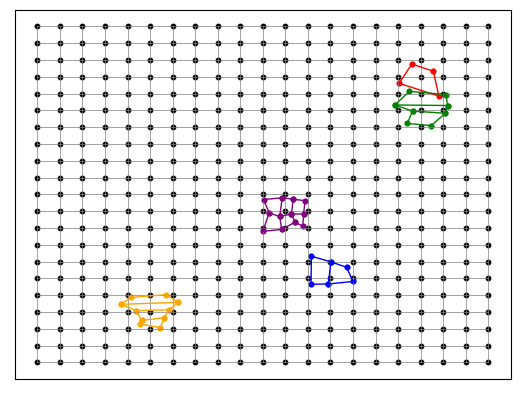

In [70]:
lim_izq,lim_der,lim_inf,lim_sup = 0,100,0,100
fig, ax = plt.subplots()
ax.xaxis.set_ticks([])
ax.yaxis.set_ticks([])
colores_grafos = ['red','blue','green','orange','purple']
sol.graficar_vecindades_grilla(fig,ax,dic_intragrilla,dic_indices)
lista_puntos_grilla = [nodo for nodo in dic_intragrilla]
sol.graficar_lista_puntos(fig,ax,lista_puntos_grilla,'black',lim_izq,lim_der,lim_inf,lim_sup)
sol.graficar_grafos(fig,ax,lista_grafos,colores_grafos,lim_izq,lim_der,lim_inf,lim_sup)
#sol.graficar_completaciones_grafos(fig,ax,lista_dic_completaciones,dic_indices,'orange',lim_izq,lim_der,lim_inf,lim_sup)
#sol.graficar_aristas_recorridas(fig,ax,L_activados,Z_activados,M_activados,lim_izq,lim_der,lim_inf,lim_sup,['purple','brown'],lista_arcos_grilla,lista_arcos_dron,nodos_por_indice,-1)

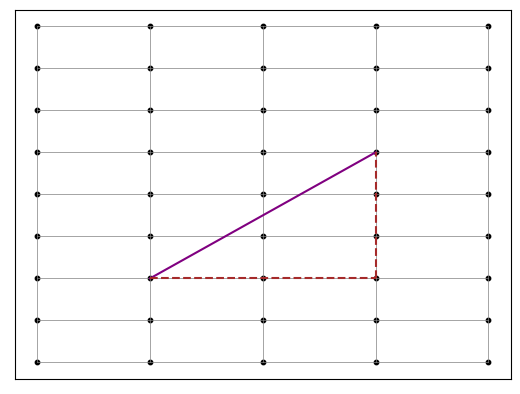

In [12]:
lim_izq,lim_der,lim_inf,lim_sup = 0,1,0,1
fig, ax = plt.subplots()
ax.xaxis.set_ticks([])
ax.yaxis.set_ticks([])
sol.graficar_vecindades_grilla(fig,ax,dic_intragrilla,dic_indices)
lista_puntos_grilla = [nodo for nodo in dic_intragrilla]
sol.graficar_lista_puntos(fig,ax,lista_puntos_grilla,'black',lim_izq,lim_der,lim_inf,lim_sup)
ax.plot([0.25,0.75],[0.25,0.625],color='purple')
ax.plot([0.25,0.75],[0.25,0.25],color='brown',linestyle='--')
ax.plot([0.75,0.75],[0.25,0.625],color='brown',linestyle='--')